# Zero-shot receptor-ligand and gene-gene analysis

This tutorials outlines how one can use the pretrained gene embeddings from the Multicellular Transformer to a) reproduce receptor-ligand results presented in the paper, b) identify potential ligands to a receptor, c) identify similar genes given a gene of interest. 

In [29]:
import pandas as pd
import torch
import json
import matplotlib.pyplot as plt

from torch.nn.functional import cosine_similarity
from sklearn.metrics import roc_curve, auc

## Load the pretrained Multicellular Transformer weights

and extract the classifier weights representing gene embeddings.

In [ ]:
# ckpt_path = "/scratch/site/u/wiatrakm/multicellular-transformer/checkpoints/best_12k_no_pseudobulk_no_gex.ckpt"
ckpt_path = "/Users/maciejwiatrak/Downloads/mct_checkpoint_12k.ckpt"


mct_embeddings = torch.load(
    ckpt_path, map_location="cpu"
)['state_dict']['model.gene_id_classifier.decoder.weight']  # extract gene embeddings from the classifier head weights

# load ENSEMBL ID to idx map
with open("data/gene_symbol2idx.json", "r") as f:
    gene_symbol2idx = json.load(f)

## Read receptor-ligand dataset with negatives

The receptor-ligand interactions have been extracted from LIANA+ [1] consensus list. The negative pairs were sampled randomly following a 1:10 positive-negative ratio.

In [25]:
rl_df = pd.read_csv("data/receptor_ligand_with_negatives.csv")
rl_df.head()

,ligand,receptor,label
0,LGALS9,PTPRC,1
1,LGALS9,MET,1
2,LGALS9,CD44,1
3,LGALS9,LRP1,1
4,LGALS9,CD47,1


#### Add cosine similarity between the pretrained embeddings from the Multicellular Transformer.

In [27]:
def compute_cosine_similarity(
    row: dict,
    gene_symbol2idx: dict,
    embeddings: torch.Tensor,
):
    lig_idx = gene_symbol2idx.get(row['ligand'], None)
    rec_idx = gene_symbol2idx.get(row['receptor'], None)
    if lig_idx is None or rec_idx is None:
        return None
    cs = cosine_similarity(embeddings[lig_idx], embeddings[rec_idx], dim=0).item()
    # normalise the CS to be between 0 and 1
    return (cs + 1) / 2


rl_df['mct_cs'] = rl_df.apply(lambda row: compute_cosine_similarity(row, gene_symbol2idx, mct_embeddings), axis=1)

### Plot the ROC curve

Using cosine similarity between pretrained Multicellular Transformer embeddings

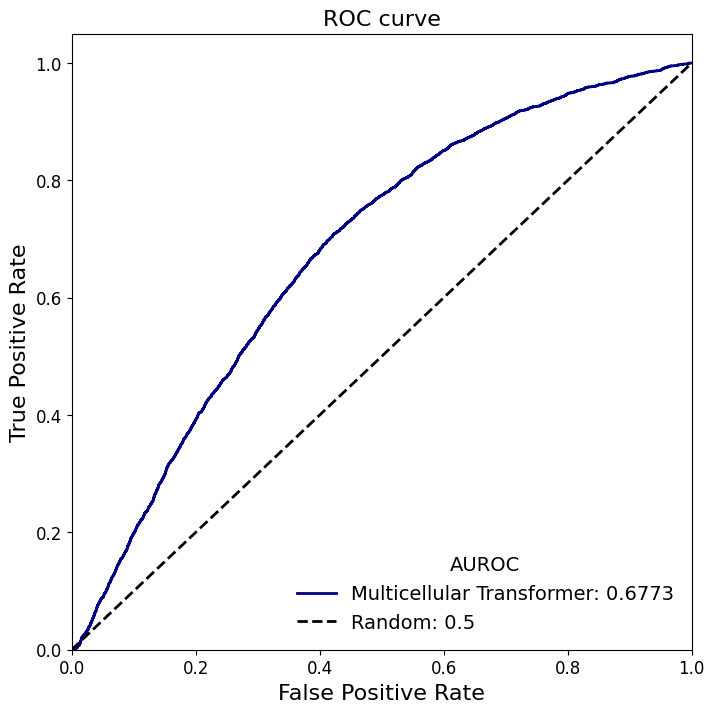

In [38]:
fpr, tpr, _ = roc_curve(rl_df['label'], rl_df['mct_cs'])
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 8))

plt.plot(fpr, tpr, color="#000080", lw=2, label=f'Multicellular Transformer: {roc_auc:.4f}')

plt.plot([0, 1], [0, 1], color='black', linestyle='--', lw=2, label=f'Random: {0.5:.1f}')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=16)
plt.ylabel('True Positive Rate', fontsize=16)
plt.title('ROC curve', fontsize=16)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(frameon=False, loc='lower right', fontsize=14, title='AUROC', title_fontsize=14)

plt.show()

## Identity candidate ligands for a receptor

In [98]:
# Select a receptor of interest and get its index
receptor = "GPR84"
# get receptor's index in Multicellular Transformer
receptor_idx = gene_symbol2idx[receptor]


# Get all ligands present in the dataset as potential candidates
# we only consider rows with label == 1
ligands = rl_df[rl_df['label'] == 1].ligand.unique()
# get ligands' indices in Multicellular Transformer
ligand_indices = [gene_symbol2idx[l] for l in ligands]

# compute cosine similarity
cs = cosine_similarity(
    mct_embeddings[receptor_idx],
    mct_embeddings[ligand_indices]
)
# extract top 25 ligands with highest cosine similarity
k = 25
vals, indices = torch.topk(cs, largest=True, k=k)
top_ligand_names = [ligands[i] for i in indices]

top_ligands_receptor = pd.DataFrame(
    {'gene_name': top_ligand_names, 'cs': vals.tolist()}
)
top_ligands_receptor.head()

,gene_name,cs
0,RNASE2,0.387480
1,CLEC4G,0.382369
2,SIRPB2,0.380121
3,LEP,0.366348
4,NCR3LG1,0.356769


#### Evaluate whether in the top 25 ligands there are any true ligands known to bind to the receptor

In [99]:
# get true ligands for a receptor
receptor_df = rl_df[rl_df['receptor'] == receptor]
true_ligands = receptor_df[receptor_df['label'] == 1].ligand.tolist()

# identify overlapping ligands
overlapping_ligands = [i for i in true_ligands if i in top_ligand_names]
print(f"Overlapping ligands: {overlapping_ligands}")

Overlapping ligands: ['AVP', 'VIP', 'GHRH', 'SCT']


## Use gene-gene cosine similarity to identify co-regulated genes

In [106]:
gene = 'CD14'
gene_idx = gene_symbol2idx[gene]

cs = cosine_similarity(
    mct_embeddings[gene_idx],
    mct_embeddings,
)
# extract top 25 genes highest cosine similarity
k = 25 + 1 # account for the embedding of the gene itself
vals, indices = torch.topk(cs, largest=True, k=k)
# do idx2gene_symbol to extract the gene names
idx2gene_symbol = {idx: gene for gene, idx in gene_symbol2idx.items()}
top_genes = [idx2gene_symbol[i.item()] for i in indices]

top_similar_genes = pd.DataFrame(
    {'gene_name': top_genes[1:], 'cs': vals[1:].tolist()}
)
top_similar_genes.head()

,gene_name,cs
0,MAFB,0.345640
1,MS4A6A,0.339345
2,MS4A7,0.323238
3,STAB1,0.319636
4,FCGR2A,0.305289


## References

[1] Dimitrov, D., Schäfer, P.S.L., Farr, E. et al. LIANA+ provides an all-in-one framework for cell–cell communication inference. Nat Cell Biol 26, 1613–1622 (2024). https://doi.org/10.1038/s41556-024-01469-w